# Curva de aprendizaje — ¿cuántas imágenes de entrenamiento hacen falta?

Este notebook **solo lee y grafica**. Los entrenamientos los ejecuta
`run_curve.py` y la evaluación `eval_curve.py`; aquí no se lanza nada pesado.

Esa separación es deliberada: el experimento son entre 18 y 52 h de GPU, y un
kernel de Jupyter abierto durante días es frágil. Los scripts son resumibles y
escriben en `resultados.json`; este notebook consume ese fichero.

```
python experiments/curva_aprendizaje/run_curve.py --models yolo11m cnn_baseline
python experiments/curva_aprendizaje/eval_curve.py
```

## Diseño del experimento

| | |
|---|---|
| Tamaños | 8 000 / 16 000 / 32 000 imágenes, **anidados** (8k ⊂ 16k ⊂ 32k) |
| Validación | las **mismas** 2 000 imágenes en los tres puntos |
| Épocas | reducidas al crecer el subset, para no confundir *más datos* con *más cómputo* |
| Semillas | 1 por punto — interesa la **forma** de la curva, no el valor exacto |
| Evaluación | protocolo común: `conf=0.001`, `max_det=100`, píxeles nativos |

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

EXP = Path.cwd() if Path.cwd().name == "curva_aprendizaje" else Path("experiments/curva_aprendizaje")
res = json.loads((EXP / "resultados.json").read_text(encoding="utf-8"))

filas = [v for v in res.values() if "map50_95" in v]
print(f"{len(filas)} runs evaluados de {len(res)} registrados")

modelos = sorted({v["model"] for v in filas})
datos = {m: sorted([v for v in filas if v["model"] == m],
                   key=lambda v: v["train_size"]) for m in modelos}
for m, f in datos.items():
    print(f"  {m}: {[v['train_size'] for v in f]}")

5 runs evaluados de 5 registrados
  cnn_baseline: [8000, 16000]
  yolo11m: [8000, 16000, 32000]


In [8]:
print(f"{'modelo':<14}{'imgs':>8}{'épocas':>8}{'mAP50':>9}{'mAP50-95':>10}"
      f"{'small':>8}{'F1':>8}{'horas':>8}")
print("-" * 73)
for m in modelos:
    for v in datos[m]:
        print(f"{m:<14}{v['train_size']:>8}{v['epochs_cap']:>8}{v['map50']:>9.2f}"
              f"{v['map50_95']:>10.2f}{v.get('map_small', float('nan')):>8.2f}"
              f"{v.get('f1', float('nan')):>8.2f}{v.get('horas', 0):>8.1f}")
    print("-" * 73)

modelo            imgs  épocas    mAP50  mAP50-95   small      F1   horas
-------------------------------------------------------------------------
cnn_baseline      8000      85    28.58     11.49    7.35   37.12     5.0
cnn_baseline     16000      58    34.57     14.20    8.61   43.90     9.1
-------------------------------------------------------------------------
yolo11m           8000      70    49.96     27.35   11.40   53.04     3.7
yolo11m          16000      50    51.24     28.71   12.52   54.16     5.1
yolo11m          32000      36    53.22     29.95   12.11   56.63     7.1
-------------------------------------------------------------------------


## La curva

Lo que se busca no es el valor absoluto sino **dónde se aplana**. Si entre 16k y
32k la ganancia es pequeña, 32k no compensa su coste; si sigue subiendo con
pendiente clara, el subset actual de 8k se está quedando corto.

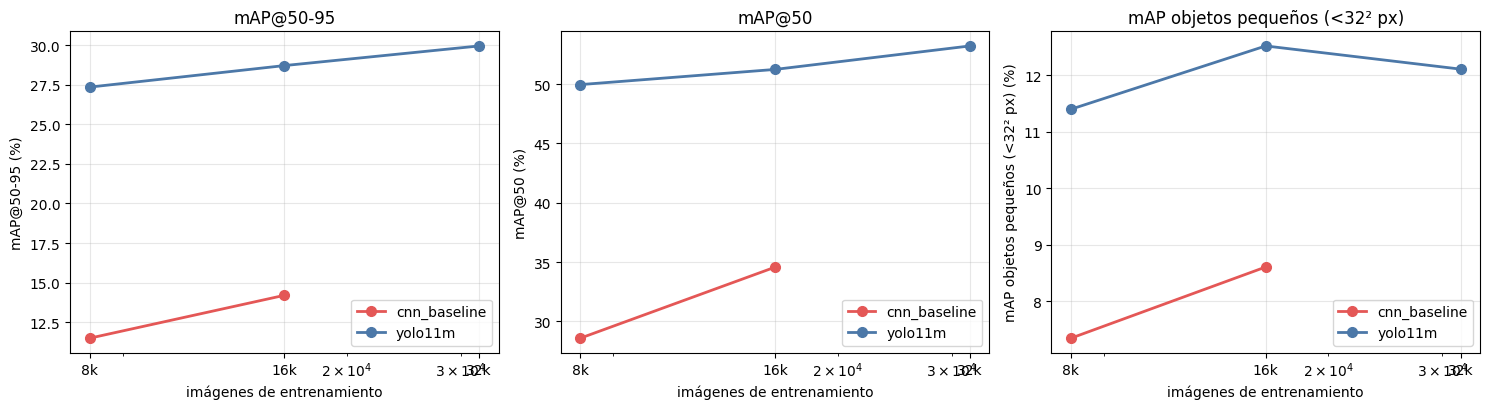

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
colores = {"yolo11m": "#4C78A8", "cnn_baseline": "#E45756"}

for ax, metrica, titulo in zip(
        axes,
        ["map50_95", "map50", "map_small"],
        ["mAP@50-95", "mAP@50", "mAP objetos pequeños (<32² px)"]):
    for m in modelos:
        x = [v["train_size"] for v in datos[m]]
        y = [v.get(metrica, np.nan) for v in datos[m]]
        ax.plot(x, y, "o-", label=m, color=colores.get(m), lw=2, ms=7)
    ax.set_xscale("log")
    ax.set_xticks([8000, 16000, 32000])
    ax.set_xticklabels(["8k", "16k", "32k"])
    ax.set_xlabel("imágenes de entrenamiento")
    ax.set_ylabel(f"{titulo} (%)")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Ganancia marginal: cuánto mAP compra cada duplicación del dataset
print("Ganancia por duplicar el número de imágenes\n")
for m in modelos:
    f = datos[m]
    print(f"  {m}")
    for a, b in zip(f, f[1:]):
        d = b["map50_95"] - a["map50_95"]
        rel = d / a["map50_95"] * 100 if a["map50_95"] else float("nan")
        coste = b.get("horas", 0) - a.get("horas", 0)
        print(f"    {a['train_size']:>6} -> {b['train_size']:<6} "
              f"{d:+6.2f} pp  ({rel:+6.1f} %)   +{coste:.1f} h")
    print()

Ganancia por duplicar el número de imágenes

  cnn_baseline
      8000 -> 16000   +2.71 pp  ( +23.6 %)   +4.0 h

  yolo11m
      8000 -> 16000   +1.36 pp  (  +5.0 %)   +1.4 h
     16000 -> 32000   +1.24 pp  (  +4.3 %)   +2.0 h



In [5]:
# Extrapolación: las curvas de aprendizaje suelen seguir una ley de potencia
# mAP ≈ a · n^b. Con solo 3 puntos el ajuste es orientativo, NO una predicción
# fiable: sirve para estimar el orden de magnitud de lo que quedaría por ganar.
print("Ajuste log-log  mAP = a · n^b   (b pequeño = curva ya plana)\n")
for m in modelos:
    f = datos[m]
    if len(f) < 3:
        print(f"  {m}: hacen falta 3 puntos")
        continue
    x = np.log([v["train_size"] for v in f])
    y = np.log([v["map50_95"] for v in f])
    b, loga = np.polyfit(x, y, 1)
    pred = lambda n: np.exp(loga) * n ** b
    print(f"  {m}:  b = {b:.3f}")
    for n in (32000, 70000):
        print(f"     n={n:>6}: mAP estimado {pred(n):5.2f}%")
    ganancia = pred(70000) - f[-1]["map50_95"]
    print(f"     pasar de {f[-1]['train_size']} a 70000 -> {ganancia:+.2f} pp estimados\n")

Ajuste log-log  mAP = a · n^b   (b pequeño = curva ya plana)

  yolo11m:  b = 0.066
     n= 32000: mAP estimado 29.98%
     n= 70000: mAP estimado 31.56%
     pasar de 32000 a 70000 -> +1.61 pp estimados



## Decisión

Rellenar tras ver los resultados:

- **Tamaño elegido para la comparativa principal:** 
- **Justificación (ganancia marginal frente a coste):** 
- **¿Difieren las curvas de YOLO y la CNN?** YOLO viene preentrenado en COCO
  *con su cabeza de detección*, así que es el modelo menos ávido de datos de los
  cinco y su curva debería saturar antes. Si es así, elegir el tamaño mirando
  solo a YOLO infraestimaría lo que necesitan DETR y la CNN.
- **Aviso:** 1 semilla por punto. Diferencias de menos de ~1 pp entre puntos
  contiguos no son distinguibles del ruido.